# Exploring Weight Distributions
This notebook shows how to load and analyze the trained weights in TensorFlow Lite neural network models.

## Software installation

Before we can load TF Lite files we need to build and install software to read the file format. This will take a few minutes to run.

First we'll build and install the Flatbuffer compiler, which takes in a schema definition and outputs Python files to read files with that format.

In [0]:
# Build and install the Flatbuffer compiler.
%cd /content/
!git clone https://github.com/google/flatbuffers
%cd flatbuffers
!cmake -G "Unix Makefiles" -DCMAKE_BUILD_TYPE=Release
!make
!cp flatc /usr/local/bin/

/content
Cloning into 'flatbuffers'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 17292 (delta 1), reused 2 (delta 0), pack-reused 17283
Receiving objects: 100% (17292/17292), 10.18 MiB | 24.02 MiB/s, done.
Resolving deltas: 100% (12003/12003), done.
/content/flatbuffers
-- The C compiler identification is GNU 7.5.0
-- The CXX compiler identification is GNU 7.5.0
-- Check for working C compiler: /usr/bin/cc
-- Check for working C compiler: /usr/bin/cc -- works
-- Detecting C compiler ABI info
-- Detecting C compiler ABI info - done
-- Detecting C compile features
-- Detecting C compile features - done
-- Check for working CXX compiler: /usr/bin/c++
-- Check for working CXX compiler: /usr/bin/c++ -- works
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Looking for strtof_l
-- Looking

We also need to fetch the TensorFlow source code so we can generate the Python interface from the schema holding the file format.

In [0]:
%cd /content/
!git clone --depth 1 https://github.com/tensorflow/tensorflow
!flatc --python --gen-object-api tensorflow/tensorflow/lite/schema/schema_v3.fbs

/content
Cloning into 'tensorflow'...
remote: Enumerating objects: 20967, done.
remote: Counting objects: 100% (20967/20967), done.
remote: Compressing objects: 100% (14875/14875), done.
remote: Total 20967 (delta 7963), reused 9495 (delta 5541), pack-reused 0
Receiving objects: 100% (20967/20967), 47.83 MiB | 12.42 MiB/s, done.
Resolving deltas: 100% (7963/7963), done.
Checking out files: 100% (21652/21652), done.


We also need to install the Python libraries we'll be using.

In [0]:
!pip install flatbuffers
import matplotlib.pyplot as plt
import numpy as np
import pprint
import re
import sys

# This hackery allows us to import the Python files we've just generated.
sys.path.append("/content/tflite/")
import Model

These utility functions will help us convert the model into a dictionary that's easy to work with in Python.

In [0]:
def CamelCaseToSnakeCase(camel_case_input):
  """Converts an identifier in CamelCase to snake_case."""
  s1 = re.sub("(.)([A-Z][a-z]+)", r"\1_\2", camel_case_input)
  return re.sub("([a-z0-9])([A-Z])", r"\1_\2", s1).lower()

def FlatbufferToDict(fb, attribute_name=None):
  """Converts a hierarchy of FB objects into a nested dict."""
  if hasattr(fb, "__dict__"):
    result = {}
    for attribute_name in dir(fb):
      attribute = fb.__getattribute__(attribute_name)
      if not callable(attribute) and attribute_name[0] != "_":
        snake_name = CamelCaseToSnakeCase(attribute_name)
        result[snake_name] = FlatbufferToDict(attribute, snake_name)
    return result
  elif isinstance(fb, str):
    return fb
  elif attribute_name == "name" and fb is not None:
    result = ""
    for entry in fb:
      result += chr(FlatbufferToDict(entry))
    return result
  elif hasattr(fb, "__len__"):
    result = []
    for entry in fb:
      result.append(FlatbufferToDict(entry))
    return result
  else:
    return fb

def CreateDictFromFlatbuffer(buffer_data):
  model_obj = Model.Model.GetRootAsModel(buffer_data, 0)
  model = Model.ModelT.InitFromObj(model_obj)
  return FlatbufferToDict(model)

## Loading a model

This example uses the Inception v3 model, dating back to 2015, but you can replace it with your own file by updating the variables.

In [0]:
MODEL_ARCHIVE_NAME = 'inception_v3_2015_2017_11_10.zip'
MODEL_ARCHIVE_URL = 'https://storage.googleapis.com/download.tensorflow.org/models/tflite/' + MODEL_ARCHIVE_NAME
MODEL_FILE_NAME = 'inceptionv3_non_slim_2015.tflite'
!curl -o {MODEL_ARCHIVE_NAME} {MODEL_ARCHIVE_URL}
!unzip {MODEL_ARCHIVE_NAME}
with open(MODEL_FILE_NAME, 'rb') as file:
 model_data = file.read()

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 84.4M  100 84.4M    0     0  57.7M      0  0:00:01  0:00:01 --:--:-- 57.7M
Archive:  inception_v3_2015_2017_11_10.zip
  inflating: inceptionv3_non_slim_2015.tflite  
  inflating: imagenet_2015_label_strings.txt  


Once we have the raw bytes of the file, we need to convert them into an understandable form. The utility functions and Python schema code we generated earlier will help us create a dictionary holding the file contents in a structured form. Since it's a large file, this will take several minutes to run.

In [0]:
model_dict = CreateDictFromFlatbuffer(model_data)

Now we have the model file in a dictionary, we can examine its contents using standard Python commands. In this case I'm interested in examining the tensors (arrays of values) in the first subgraph, so I'm printing them out.

In [0]:
pprint.pprint(model_dict['subgraphs'][0]['tensors'])

[{'buffer': 206,
  'name': 'Mul',
  'quantization': {'max': [255.0],
                   'min': [0.0],
                   'scale': None,
                   'zero_point': None},
  'shape': [1, 299, 299, 3],
  'type': 0},
 {'buffer': 260,
  'name': 'conv',
  'quantization': {'max': None, 'min': None, 'scale': None, 'zero_point': None},
  'shape': [1, 149, 149, 32],
  'type': 0},
 {'buffer': 71,
  'name': 'conv/Conv2D_bias',
  'quantization': {'max': None, 'min': None, 'scale': None, 'zero_point': None},
  'shape': [32],
  'type': 0},
 {'buffer': 186,
  'name': 'conv/conv2d_params',
  'quantization': {'max': None, 'min': None, 'scale': None, 'zero_point': None},
  'shape': [32, 3, 3, 3],
  'type': 0},
 {'buffer': 261,
  'name': 'conv_1',
  'quantization': {'max': None, 'min': None, 'scale': None, 'zero_point': None},
  'shape': [1, 147, 147, 32],
  'type': 0},
 {'buffer': 70,
  'name': 'conv_1/Conv2D_bias',
  'quantization': {'max': None, 'min': None, 'scale': None, 'zero_point': None},
  

I want to inspect the weight parameters of a typical convolution layer, so looking at the output above I can see that the tensor with the name 'conv/conv2d_params' has a buffer index of 186. This index points to where the raw bytes for the trained weights are stored. From the tensor properties I can see its type is '0', which [corresponds to a type of float32](https://github.com/tensorflow/tensorflow/blob/master/tensorflow/lite/schema/schema_v3.fbs#L30).

This means we have to cast the bytes into a numpy array using the frombuffer() function.

In [0]:
param_bytes = bytearray(model_dict['buffers'][186]['data'])
params = np.frombuffer(param_bytes, dtype=np.float32)

With the weights loaded into a numpy array, we can now use all the standard functionality to analyze them. To start, let's print out the minimum and maximum values to understand the range.

In [0]:
params.min()

-5.4024096

In [0]:
params.max()

4.4646473

This gives us the total range of the weight values, but how are those parameters distributed across that range?

(array([ 1.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  0.,  1.,
         0.,  0.,  0.,  0.,  1.,  1.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,
         1.,  0.,  0.,  1.,  1.,  1.,  0.,  0.,  2.,  1.,  3.,  1.,  1.,
         2.,  3.,  1.,  0.,  3.,  2.,  2.,  1.,  1.,  0.,  3.,  5.,  6.,
         1.,  4.,  4.,  1.,  4.,  6.,  9.,  6.,  6., 15., 14., 14., 12.,
        22., 19., 10., 21., 24., 31., 33., 29., 39., 37., 41., 51., 43.,
        33., 29., 32., 18., 21., 16., 15., 22., 18., 10., 10.,  8.,  8.,
         7.,  4.,  2.,  3.,  4.,  4.,  4.,  4.,  5.,  2.,  2.,  2.,  3.,
         2.,  3.,  0.,  4.,  0.,  3.,  1.,  3.,  1.

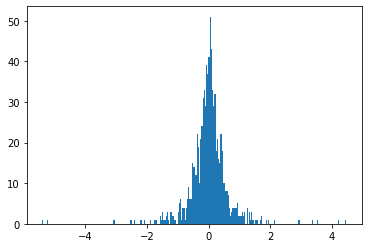

In [0]:
plt.hist(params, 256)

This shows a distribution that's heavily concentrated around zero, with just a few outliers. 